# phase 1-3：建模範圍 EDA —— 什麼時候、哪些站最容易借不到車

**資料範圍**：2026-10-01 ~ 10-18（18 天）、建模範圍「大安區 + 臺大公館校區」共 279 站（大安區 214、校區 65）、每 5 分鐘一筆。
為什麼要加校區：API 把臺大校園裡的站另外標成「臺大公館校區」，只篩大安區會把校園切成兩半（見 `docs/DECISIONS.md` 2026-10-19）。
9/30 只收了半天所以不用；10/6 凌晨有一段 334 分鐘的空洞，保留不刪（圖上那段只是比較少點）。

**本頁說的「借不到車的比例」** = 在所有「(站, 時間點)」裡，可借車輛 <= 1 的佔多少。
預測目標還沒定案（<= 0 或 <= 1，見 `docs/DECISIONS.md`），這裡主要看 <= 1，需要時兩個都列。

| 步驟 | 想回答的問題 |
|---|---|
| 1-3a | 資料讀進來了嗎、量對不對 |
| 1-3b | 每天的比例穩定嗎？上班日和休息日差多少？ |
| 1-3c | 一週裡、一天裡，什麼時候最容易借不到？ |
| 1-3d | 問題集中在少數站，還是到處都有？ |
| 1-3e | 空了會持續多久？為什麼「維持現狀」baseline 很強卻卡在 7 成？ |
| 1-3f | 下雨有沒有影響？ |

## 1-3a 環境準備與讀資料

先把套件、圖表樣式和資料準備好。資料都透過 `youbike.data.load_snapshots()` 讀，
跟 baseline 用的是同一份載入邏輯 —— 不在 notebook 裡自己讀檔，免得兩邊算出不一樣的東西。

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from IPython.display import display

from youbike.data import MODEL_DISTRICTS, MODEL_SCOPE_NAME, load_snapshots
from youbike.dataset import make_labels
from youbike.weather import load_weather, rain_increment, DAAN_STATIONS

# numpy 對 pandas 內部的時間運算會丟 DeprecationWarning，跟我們的程式無關，先關掉免得洗版
warnings.filterwarnings("ignore", category=DeprecationWarning)

# 分析範圍：9/30 下午才開始收，只有半天，所以從 10/1 開始
START, END = "2026-10-01", "2026-10-18"
# 建模範圍：大安區 + 臺大公館校區（API 把臺大校園的站另外標成「臺大公館校區」，
# 只篩大安區會把校園切成兩半，見 docs/DECISIONS.md 2026-10-19）
DISTRICT = MODEL_DISTRICTS

# 國定假日。不能只看「星期幾」—— 國慶日 10/10 是週六，前一天 10/9（週五）補假，
# 那天的樣子跟週末一樣（1-3b 會看到）。之後資料變多，這裡要換成完整的行事曆。
HOLIDAYS = {"2026-10-09": "國慶日補假"}

WEEKDAY_ZH = ["一", "二", "三", "四", "五", "六", "日"]

In [2]:
# --- 圖表樣式 ---
# 顏色：上班日用藍、休息日用橘（兩個顏色在色盲模擬下也分得開）；
# 「多少」這種連續數值用同一個藍色由淺到深（顏色越深 = 越容易借不到）。
SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
C_WORK, C_OFF = "#2a78d6", "#eb6834"
BLUES = LinearSegmentedColormap.from_list(
    "blues", ["#f2f7fd", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])

# 中文字型：Windows 用微軟正黑體，Mac / Linux 依序找後面的字型。
# 先查電腦上「有」哪一個再用，不直接把整串丟給 matplotlib ——
# 它每找不到一個就印一次警告，會把輸出洗版。
from matplotlib import font_manager
_installed = {f.name for f in font_manager.fontManager.ttflist}
CJK_FONT = next((f for f in ["Microsoft JhengHei", "PingFang TC", "Noto Sans CJK TC"]
                 if f in _installed), "sans-serif")

plt.rcParams.update({
    "font.family": CJK_FONT,
    "axes.unicode_minus": False,          # 中文字型常常缺「負號」這個字，改用一般的減號
    "figure.dpi": 110,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True,               # 格線畫在資料後面
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 2,
    "legend.frameon": False,
})
PCT = mtick.PercentFormatter(1.0, decimals=0)   # 0.25 -> 25%

In [3]:
df = load_snapshots(start=START, end=END, district=DISTRICT, with_station_info=True, verbose=False)
N_ST = df["station_id"].nunique()   # 圖表標題用


def day_type(date_str):
    """上班日 / 休息日（週末 + 國定假日）。"""
    if date_str in HOLIDAYS or pd.Timestamp(date_str).weekday() >= 5:
        return "休息日"
    return "上班日"


# 先對「不重複的日期」算，再 map 回去 —— 比每一列各算一次快幾萬倍
df["day_type"] = df["date"].map({d: day_type(d) for d in df["date"].unique()})
df["empty0"] = df["bikes_available"] <= 0   # 完全沒車
df["empty1"] = df["bikes_available"] <= 1   # 只剩 0~1 台（目前傾向的預測目標）

n_points = df.groupby("date")["src_time"].nunique()
print(f"{MODEL_SCOPE_NAME}：{len(df):,} 列、{N_ST} 站、{df['date'].nunique()} 天")
print("各區站數：", df.drop_duplicates("station_id")["district"].value_counts().to_dict())
print(f"每天的時間點：最少 {n_points.min()}（{n_points.idxmin()}）、中位數 {int(n_points.median())}，滿載是 288")
print(f"上班日 {(df.groupby('date')['day_type'].first() == '上班日').sum()} 天、"
      f"休息日 {(df.groupby('date')['day_type'].first() == '休息日').sum()} 天")
df[["time_taipei", "name", "total_docks", "bikes_available", "day_type"]].head()

大安區 + 臺大公館校區：1,416,034 列、279 站、18 天
各區站數： {'大安區': 214, '臺大公館校區': 65}
每天的時間點：最少 222（2026-10-06）、中位數 287，滿載是 288


上班日 11 天、休息日 7 天


,time_taipei,name,total_docks,bikes_available,day_type
0,2026-10-01 00:00:22+08:00,YouBike2.0_捷運科技大樓站,28,11,上班日
1,2026-10-01 00:05:19+08:00,YouBike2.0_捷運科技大樓站,28,15,上班日
2,2026-10-01 00:10:22+08:00,YouBike2.0_捷運科技大樓站,28,14,上班日
3,2026-10-01 00:15:18+08:00,YouBike2.0_捷運科技大樓站,28,15,上班日
4,2026-10-01 00:20:19+08:00,YouBike2.0_捷運科技大樓站,28,13,上班日


**讀到了什麼**：約 142 萬列 = 279 站 × 18 天 × 每天約 285 個時間點。
只有 10/6 明顯偏少（凌晨那個洞），其他天都接近滿載，可以放心往下做。

## 1-3b 整體輪廓：每天的比例穩定嗎？

先不分時段、不分站，看「每一天」整個建模範圍借不到車的比例。
這一步是在找「哪幾天特別怪」—— 怪的日子通常就是某個特徵的線索。

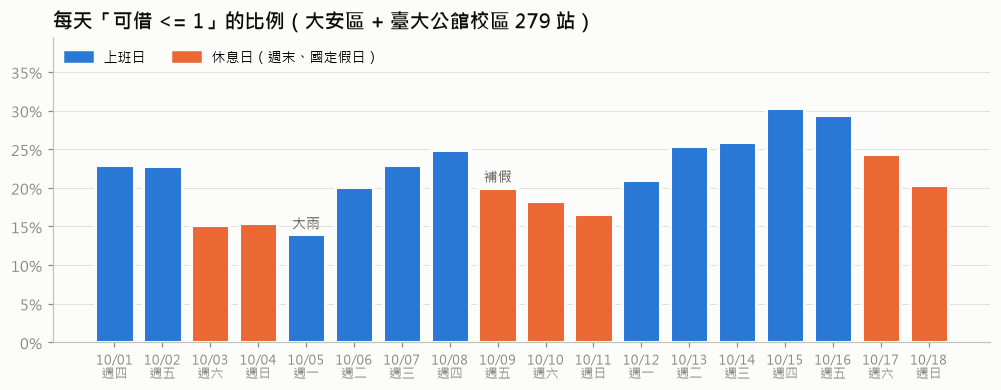

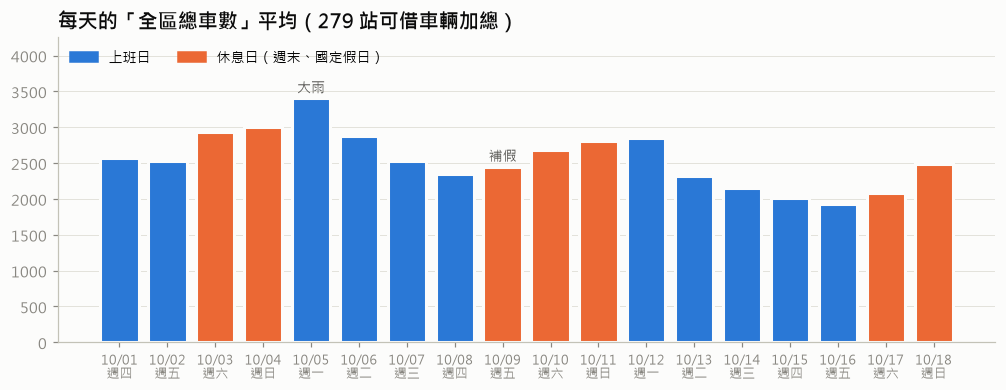

上班日 vs 休息日：
          可借 <= 0 (%)  可借 <= 1 (%)
day_type                          
上班日              12.1         23.7
休息日               8.7         18.6


In [4]:
daily = (df.groupby("date")
           .agg(empty0=("empty0", "mean"), empty1=("empty1", "mean"))
           .assign(day_type=lambda d: d.index.map(day_type)))

# 全區總車數：每個時間點把範圍內所有站的可借車輛加起來，再取每天的平均
daily["total_bikes"] = (df.groupby(["date", "src_time"])["bikes_available"].sum()
                          .groupby("date").mean().round(0))

NOTES = {"2026-10-05": "大雨", "2026-10-09": "補假"}
labels = [f"{d[5:7]}/{d[8:]}\n週{WEEKDAY_ZH[pd.Timestamp(d).weekday()]}" for d in daily.index]
colors = [C_WORK if t == "上班日" else C_OFF for t in daily["day_type"]]
legend = [Patch(color=C_WORK, label="上班日"), Patch(color=C_OFF, label="休息日（週末、國定假日）")]
x = np.arange(len(daily))


def bar_by_day(ax, values, title, fmt=None):
    ax.bar(x, values, color=colors, width=0.8, edgecolor=SURFACE, linewidth=2)
    ax.set_xticks(x, labels, fontsize=8.5)
    ax.grid(axis="x", visible=False)
    ax.set_title(title)
    ax.legend(handles=legend, loc="upper left", ncol=2, fontsize=9)
    for d, note in NOTES.items():
        i = daily.index.get_loc(d)
        ax.annotate(note, (i, values.iloc[i]), xytext=(0, 4), textcoords="offset points",
                    ha="center", fontsize=9, color=INK2)
    if fmt:
        ax.yaxis.set_major_formatter(fmt)


fig, ax = plt.subplots(figsize=(11, 3.6))
bar_by_day(ax, daily["empty1"], f"每天「可借 <= 1」的比例（{MODEL_SCOPE_NAME} {N_ST} 站）", PCT)
ax.set_ylim(0, daily["empty1"].max() * 1.3)
plt.show()

fig, ax = plt.subplots(figsize=(11, 3.6))
bar_by_day(ax, daily["total_bikes"], f"每天的「全區總車數」平均（{N_ST} 站可借車輛加總）")
ax.set_ylim(0, daily["total_bikes"].max() * 1.25)
plt.show()

by_type = df.groupby("day_type")[["empty0", "empty1"]].mean()
print("上班日 vs 休息日：")
print((by_type * 100).round(1).rename(columns={"empty0": "可借 <= 0 (%)", "empty1": "可借 <= 1 (%)"}))

**看到了什麼**

1. **上班日比休息日容易借不到**：上班日約 24%、休息日約 19%（<= 0 則是約 12% 對 9%）。
2. **10/9（週五）比前後的上班日低**（約 20%，前兩天是 23 ~ 25%）：那天是國慶日補假。
   只看大安區時這個差異更明顯（約 15%，跟週末一樣）；加進校區後被沖淡了一些 ——
   校區的節奏跟上不上班的關係比較小（見 1-3c）。「是不是假日」仍然**不能只看星期幾**，要有國定假日的行事曆。
3. **10/5（週一）大雨那天是 18 天裡最低的（約 14%）**，而且那天全區總車數是 18 天裡最多的 ——
   下大雨騎車的人少，車子都停在站裡。1-3f 會再看雨。
4. **10/13 ~ 10/16 明顯變高（升到 25 ~ 30%）**：同一段時間全區總車數從 10/12 的約 2840 台一路掉到 10/16 的約 1920 台，
   少了 3 成，週末才回升。這不是少數幾站的問題，而是**整區的車被騎走、沒有補回來**。

**對建模的意義**

- 「全區（或附近）現在總共有多少車」可能是個好特徵 —— 光看單一站看不到這種整區的變化。
- 資料的樣子**會隨時間漂移**：如果測試期剛好落在 10/13 那種週，分數會跟其他週差很多。
  這再次說明為什麼一定要照時間切，而且之後評估最好看不只一段測試期。

## 1-3c 尖峰在哪：一週 × 一天

把比例拆到「星期幾 × 幾點」。每一格是那個星期幾、那個小時裡，
所有 (站, 時間點) 中可借 <= 1 的比例。補假的 10/9 先拿掉，不然會把週五的格子拉低。

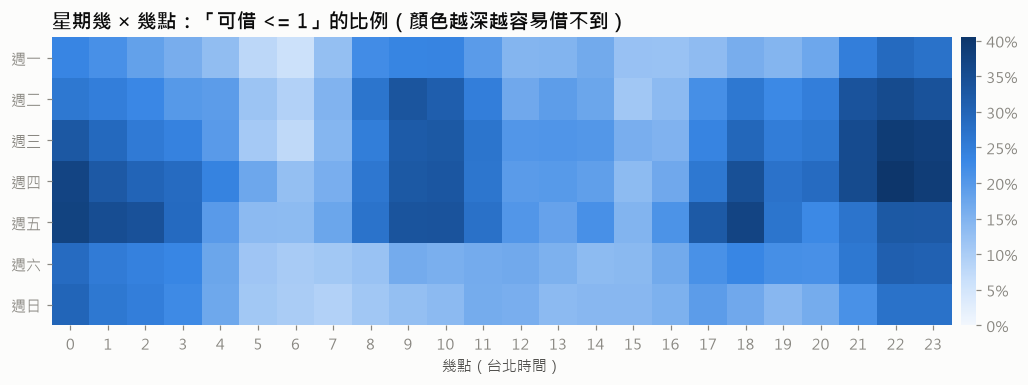

In [5]:
heat = (df[~df["date"].isin(HOLIDAYS)]
          .groupby(["weekday", "hour"])["empty1"].mean().unstack())

fig, ax = plt.subplots(figsize=(11, 3.4))
im = ax.imshow(heat.values, aspect="auto", cmap=BLUES, vmin=0, vmax=heat.values.max())
ax.set_yticks(range(7), [f"週{w}" for w in WEEKDAY_ZH])
ax.set_xticks(range(24), [str(h) for h in range(24)])
ax.set_xlabel("幾點（台北時間）")
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, format=PCT, fraction=0.03, pad=0.01)
cb.outline.set_visible(False)
ax.set_title("星期幾 × 幾點：「可借 <= 1」的比例（顏色越深越容易借不到）")
plt.show()

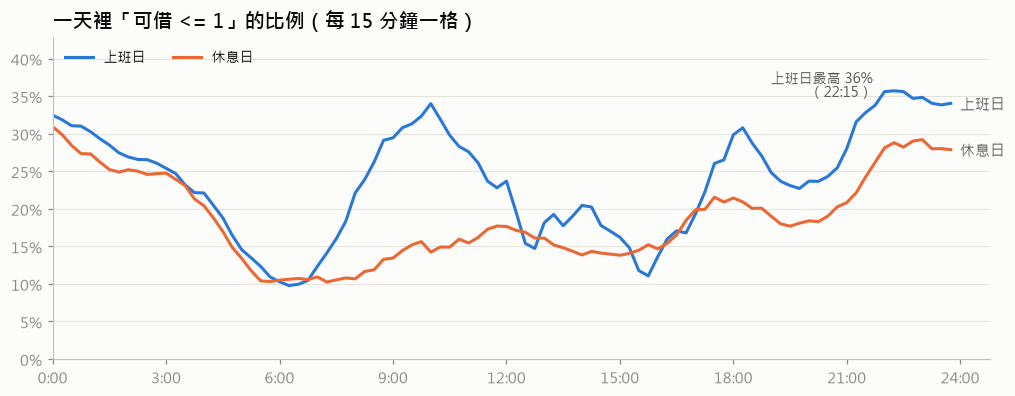

上班日：最高 35.7%（22.25 點）、最低 9.8%（6.25 點）
休息日：最高 30.9%（0.00 點）、最低 10.3%（7.25 點）


In [6]:
# 一天裡的變化：每 15 分鐘一格，上班日和休息日各一條線
df["tod"] = df["hour"] + (df["minute"] // 15) * 15 / 60     # 一天中的時間（小時，例如 8.25 = 8:15）
curve = df.groupby(["day_type", "tod"])["empty1"].mean().unstack(0)

fig, ax = plt.subplots(figsize=(11, 3.8))
for col, color in [("上班日", C_WORK), ("休息日", C_OFF)]:
    ax.plot(curve.index, curve[col], color=color, label=col)
    ax.annotate(col, (curve.index[-1], curve[col].iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=10, color=INK2)
# 標出上班日最高點（在右半邊的話文字放左邊，免得撞到線尾的標籤）
peak_t = curve["上班日"].idxmax()
right_side = peak_t > 16
ax.annotate(f"上班日最高 {curve['上班日'].max():.0%}\n（{int(peak_t)}:{int(peak_t % 1 * 60):02d}）",
            (peak_t, curve["上班日"].max()), xytext=(-14 if right_side else 14, -4), textcoords="offset points",
            ha="right" if right_side else "left", fontsize=9, color=INK2)
ax.set_xticks(range(0, 25, 3), [f"{h}:00" for h in range(0, 25, 3)])
ax.set_xlim(0, 24.8)
ax.set_ylim(0, curve.values.max() * 1.2)
ax.yaxis.set_major_formatter(PCT)
ax.legend(loc="upper left", ncol=2, fontsize=9)
ax.set_title("一天裡「可借 <= 1」的比例（每 15 分鐘一格）")
plt.show()

for col in curve:
    s = curve[col]
    print(f"{col}：最高 {s.max():.1%}（{s.idxmax():.2f} 點）、最低 {s.min():.1%}（{s.idxmin():.2f} 點）")

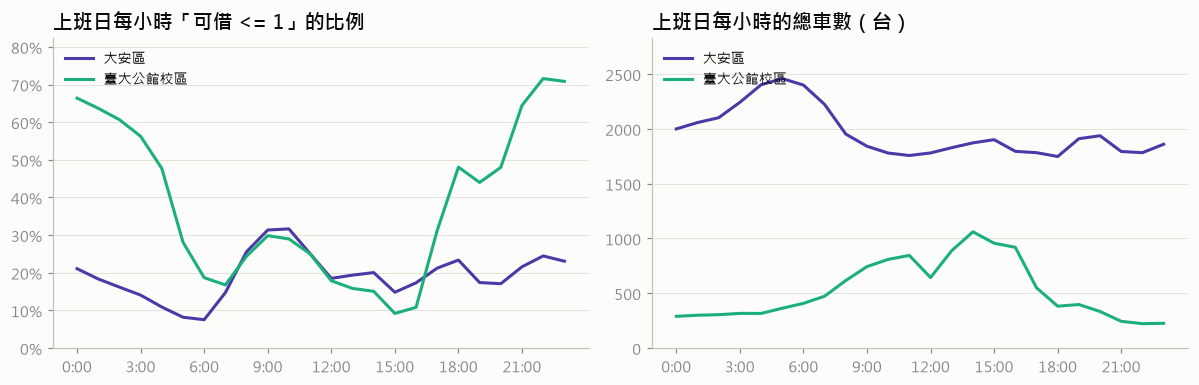

hour      3:00  10:00  15:00  22:00
district                           
大安區       14.1   31.7   14.8   24.5
臺大公館校區    56.3   29.0    9.2   71.6


In [7]:
# 上面的曲線有兩個高峰，是不是兩個區各自貢獻一個？把兩區分開畫（只看上班日）
C_DAAN, C_CAMPUS = "#4a3aa7", "#1baf7a"   # 紫、綠：跟「上班日 / 休息日」的藍橘分開，免得看錯
work = df[df["day_type"] == "上班日"]
by_dist = work.groupby(["hour", "district"])["empty1"].mean().unstack()
# 每區的總車數（每個時間點加總，再取每小時平均）—— 用來看車子白天流進校園、晚上流出
bikes = (work.groupby(["district", "src_time", "hour"])["bikes_available"].sum()
             .groupby(["hour", "district"]).mean().unstack())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for col, color in [("大安區", C_DAAN), ("臺大公館校區", C_CAMPUS)]:
    for ax, data in ((axes[0], by_dist), (axes[1], bikes)):
        ax.plot(data.index, data[col], color=color, label=col)
axes[0].yaxis.set_major_formatter(PCT)
axes[0].set_ylim(0, by_dist.values.max() * 1.15)
axes[0].set_title("上班日每小時「可借 <= 1」的比例")
axes[1].set_ylim(0, bikes.values.max() * 1.15)
axes[1].set_title("上班日每小時的總車數（台）")
for ax in axes:
    ax.set_xticks(range(0, 24, 3), [f"{h}:00" for h in range(0, 24, 3)])
    ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

print((by_dist.loc[[3, 10, 15, 22]] * 100).round(1).rename(index=lambda h: f"{h}:00").T.to_string())

**看到了什麼**

1. **上班日有兩個高峰**：早上 10:00 左右（約 34%）和晚上 22:15 左右（約 36%）。
   最低在清晨 6 點左右（約 10%）。
2. **兩個高峰分別來自兩個區，而且兩區的節奏剛好相反**（上面那組兩張圖）：
   - **大安區**是「通勤型」：早上 9 ~ 10 點最難借（約 32%），下午最輕鬆。
     最高點比我們在覆蓋率檢查裡定義的「早上尖峰 07:00-10:00」晚了一點 —— 7 點才開始上升，車子要被騎走一陣子站才會空。
     另外，大安區的總車數半夜會一路增加、清晨 5 點最多，可能是調度車半夜在補車（還沒驗證，但比之前只是猜測多了一點證據）。
   - **臺大公館校區**是「校園型」：白天車子一路流進校園（總車數從清晨約 300 台累積到下午 2 點約 1,060 台），
     下午 3 點只有約 9% 借不到；**晚上大家騎車離開，22 點有超過 7 成的站可借 <= 1**，一直空到半夜。
3. **休息日沒有早上的尖峰**，白天大多在 13 ~ 22%，最高在半夜（約 31%，同樣是校區造成的）。
4. 熱力圖裡同一個時段、不同的平日（週一 ~ 週五）也不太一樣，但每個星期幾只有 2 ~ 3 天資料，
   現在還分不清是「星期幾的差別」還是「那幾天剛好怎樣」（例如 10/13 那週全區缺車）。

**對建模的意義**：「幾點」和「上班日 / 休息日」一定要放進去，而且要能**交互作用**。
更重要的是，**同一個時刻，校區和大安區的風險可能完全相反** —— 模型一定要知道「這是哪一類站」
（例如所屬區、或站自己在這個時段的歷史空站率），不然它只會學到兩種節奏的平均，兩邊都猜不準。
樹模型（LightGBM）天生就能學這種「時段 × 站的類型」的組合。

## 1-3d 哪些站最常空

每個站算一個數字：18 天裡有多少比例的時間「完全沒車（<= 0）」，
然後看兩件事：(1) 問題集不集中；(2) 最常空的站在哪裡。

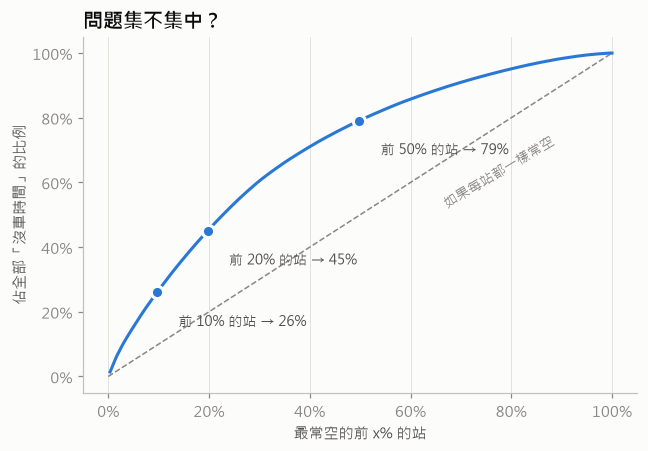

每站「沒車時間」比例：中位數 7.7%、最高 41.9%、最低 0.04%；18 天裡從沒空過的站：0 站
車柱數跟沒車比例的相關係數：-0.09（接近 0 = 幾乎沒關係）


站名,行政區,車柱數,可借 <= 0,可借 <= 1
臺大小小福西南側,臺大公館校區,10,41.9%,67.0%
臺大二號館,臺大公館校區,10,41.2%,64.0%
臺大共同教室東南側,臺大公館校區,12,40.8%,56.8%
臺大森林館北側,臺大公館校區,10,39.6%,51.1%
臺大電機二館東南側,臺大公館校區,14,36.8%,53.0%
臺大管理學院一館,臺大公館校區,17,32.5%,44.3%
臺大圖資系館北側,臺大公館校區,51,32.5%,42.2%
臺大教研館北側,臺大公館校區,26,31.4%,43.8%
臺大共同教室北側,臺大公館校區,68,29.4%,43.3%
臺大博理館東側,臺大公館校區,24,28.2%,44.3%


In [8]:
st = (df.groupby("station_id")
        .agg(name=("name", "first"), district=("district", "first"),
             lat=("lat", "first"), lon=("lon", "first"),
             docks=("total_docks", "median"),
             empty0=("empty0", "mean"), empty1=("empty1", "mean"))
        .sort_values("empty0", ascending=False))
st["name"] = st["name"].str.replace("YouBike2.0_", "", regex=False)

# 累積佔比：最常空的前 x% 的站，佔了全部「沒車時間」的多少
share = st["empty0"].cumsum() / st["empty0"].sum()
frac = np.arange(1, len(st) + 1) / len(st)

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.plot([0, 1], [0, 1], color=MUTED, linewidth=1, linestyle="--")
ax.annotate("如果每站都一樣常空", (0.66, 0.52), fontsize=9, color=MUTED, rotation=31)
ax.plot(frac, share, color=C_WORK)
for p in (0.1, 0.2, 0.5):
    i = int(len(st) * p) - 1
    ax.plot(frac[i], share.iloc[i], "o", color=C_WORK, markersize=8,
            markeredgecolor=SURFACE, markeredgewidth=2)
    ax.annotate(f"前 {p:.0%} 的站 → {share.iloc[i]:.0%}", (frac[i], share.iloc[i]),
                xytext=(14, -22), textcoords="offset points", fontsize=9, color=INK2)
ax.xaxis.set_major_formatter(PCT)
ax.yaxis.set_major_formatter(PCT)
ax.grid(axis="both")
ax.set_xlabel("最常空的前 x% 的站")
ax.set_ylabel("佔全部「沒車時間」的比例")
ax.set_title("問題集不集中？")
plt.show()

print(f"每站「沒車時間」比例：中位數 {st['empty0'].median():.1%}、最高 {st['empty0'].max():.1%}、"
      f"最低 {st['empty0'].min():.2%}；18 天裡從沒空過的站：{(st['empty0'] == 0).sum()} 站")
print(f"車柱數跟沒車比例的相關係數：{st['docks'].corr(st['empty0']):.2f}（接近 0 = 幾乎沒關係）")

top = st.head(10)[["name", "district", "docks", "empty0", "empty1"]].copy()
top.columns = ["站名", "行政區", "車柱數", "可借 <= 0", "可借 <= 1"]
top["車柱數"] = top["車柱數"].astype(int)
display(top.style.format({"可借 <= 0": "{:.1%}", "可借 <= 1": "{:.1%}"}).hide(axis="index"))

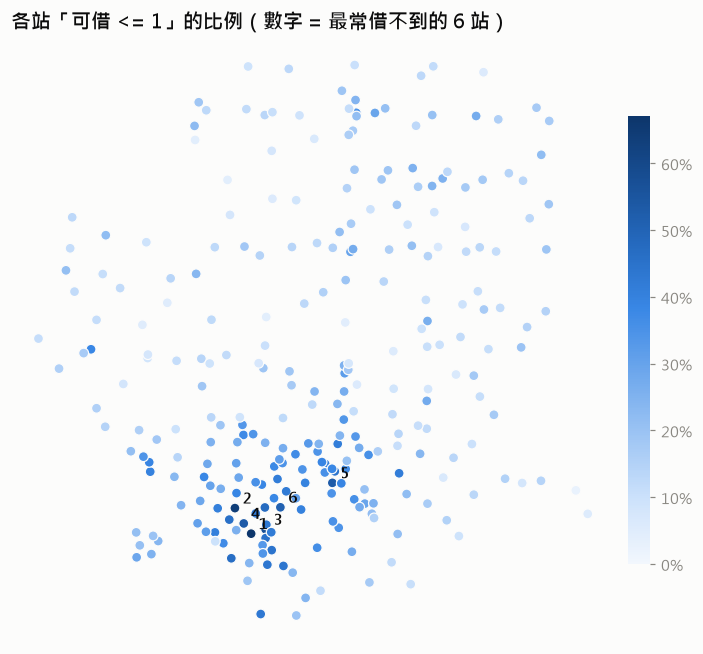

編號,站名,行政區,車柱數,可借 <= 1
1,臺大小小福西南側,臺大公館校區,10,67.0%
2,臺大二號館,臺大公館校區,10,64.0%
3,臺大共同教室東南側,臺大公館校區,12,56.8%
4,臺大第二行政大樓南側,臺大公館校區,27,53.0%
5,臺大電機二館東南側,臺大公館校區,14,53.0%
6,臺大森林館北側,臺大公館校區,10,51.1%


In [9]:
# 地圖：每個點是一個站，顏色越深 = 越常「可借 <= 1」
fig, ax = plt.subplots(figsize=(7.5, 7.5))
sc = ax.scatter(st["lon"], st["lat"], c=st["empty1"], cmap=BLUES, vmin=0, s=42,
                edgecolors=SURFACE, linewidths=0.8)
# 經緯度在台北 1 度經度比 1 度緯度短，用 1/cos(緯度) 把比例調正，地圖才不會被拉扁
ax.set_aspect(1 / np.cos(np.radians(25.03)))
# 站名直接寫在圖上會互相重疊，所以圖上只標編號，名字列在下面的表
worst = st.sort_values("empty1", ascending=False).head(6)
for i, (_, r) in enumerate(worst.iterrows(), 1):
    ax.annotate(str(i), (r["lon"], r["lat"]), xytext=(5, 3), textcoords="offset points",
                fontsize=10, fontweight="bold", color=INK)
cb = fig.colorbar(sc, ax=ax, format=PCT, fraction=0.035, pad=0.02)
cb.outline.set_visible(False)
ax.set_xticks([]); ax.set_yticks([])
for s in ax.spines.values():
    s.set_visible(False)
ax.grid(False)
ax.set_title("各站「可借 <= 1」的比例（數字 = 最常借不到的 6 站）")
plt.show()

legend_tbl = worst[["name", "district", "docks", "empty1"]].copy()
legend_tbl.insert(0, "編號", range(1, len(worst) + 1))
legend_tbl.columns = ["編號", "站名", "行政區", "車柱數", "可借 <= 1"]
legend_tbl["車柱數"] = legend_tbl["車柱數"].astype(int)
display(legend_tbl.style.format({"可借 <= 1": "{:.1%}"}).hide(axis="index"))

**看到了什麼**

1. **有集中，但沒有到「只有幾站有問題」**：最常空的前 10% 的站佔了約 1/4 的沒車時間、
   前 20% 佔約 45%；**每一站都至少空過**。
2. **最常空的前 15 站全部是臺大公館校區的站**（小小福、二號館、共同教室、森林館、電機二館……），
   最嚴重的「小小福西南側」有約 2/3 的時間可借 <= 1。這正是加入校區的理由：只看大安區的話，
   這一整群最難借的站都不在範圍裡。大安區裡最常空的則是銘傳國小、羅斯福路沿線、和平高中和臺大周邊（社科院圖書館）。
3. **車柱多不代表不會空**：相關係數只有約 −0.1，幾乎沒有關係。

順帶一提：熱門的校區站車柱都不多（10 ~ 17 個），晚上一下子就被借光。

**對建模的意義**：每個站有自己的「個性」，同一個時段不同站的風險差很多。
可以考慮的特徵：站的歷史空站率（**只能用訓練期算**，不能偷看測試期）、
站在不在校園 / 捷運出口、附近幾站現在的狀況（地圖上空站是成群出現的）。

## 1-3e 空了會持續多久？「維持現狀」為什麼卡在 7 成？

這一步跟模型最直接相關。phase 2 的 baseline 結果是：「維持現狀」（現在 <= 1 就猜 30 分鐘後也 <= 1）
PR-AUC 最好，但怎麼調都到不了 80% 的精確率。這裡把原因拆開來看。

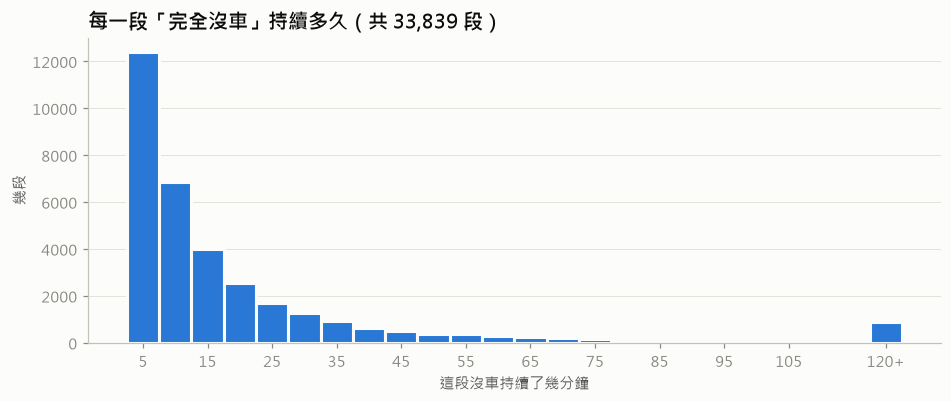

中位數 10 分鐘；48% 的段 <= 10 分鐘就恢復；17% 的段 >= 30 分鐘、7% 的段 >= 1 小時
但如果用「時間」算：全部沒車的時間裡，有 61% 是落在 >= 30 分鐘的長段


In [10]:
# 「一段沒車」= 同一站連續好幾筆都是 0 台。中間斷超過 7.5 分鐘（= 漏了一筆以上）就切開，
# 免得把資料空洞誤認成「一直沒車」。
d = df.sort_values(["station_id", "src_time"]).reset_index(drop=True)
gap = d.groupby("station_id")["src_time"].diff().dt.total_seconds() / 60
cut = (d["station_id"] != d["station_id"].shift()) | (gap > 7.5) | (d["empty0"] != d["empty0"].shift())
spell_id = cut.cumsum()
e = d["empty0"]
spells = d[e].groupby(spell_id[e]).agg(start=("src_time", "first"), end=("src_time", "last"))
# 持續時間 = 最後一筆 − 第一筆 + 一個取樣間隔（只有 1 筆的就算 5 分鐘）
spells["minutes"] = (spells["end"] - spells["start"]).dt.total_seconds() / 60 + 5

m = spells["minutes"]
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.hist(m.clip(upper=122), bins=np.arange(2.5, 127.5, 5), color=C_WORK,
        edgecolor=SURFACE, linewidth=2)
ax.set_xticks(list(range(5, 115, 10)) + [120], [str(v) for v in range(5, 115, 10)] + ["120+"])
ax.set_xlabel("這段沒車持續了幾分鐘")
ax.set_ylabel("幾段")
ax.grid(axis="x", visible=False)
ax.set_title(f"每一段「完全沒車」持續多久（共 {len(m):,} 段）")
plt.show()

print(f"中位數 {m.median():.0f} 分鐘；{(m <= 10).mean():.0%} 的段 <= 10 分鐘就恢復；"
      f"{(m >= 30).mean():.0%} 的段 >= 30 分鐘、{(m >= 60).mean():.0%} 的段 >= 1 小時")
print(f"但如果用「時間」算：全部沒車的時間裡，有 {m[m >= 30].sum() / m.sum():.0%} 是落在 >= 30 分鐘的長段")

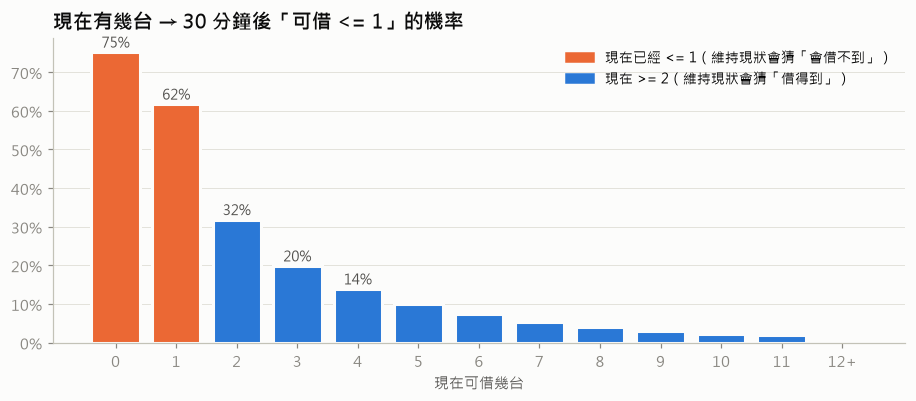

整體：30 分鐘後 <= 1 的比例（base rate）21.6%
現在 <= 1 的時候，30 分鐘後仍 <= 1：68.4%   ← 維持現狀的「精確率」
30 分鐘後 <= 1 的情況裡，現在就已經 <= 1：68.5%   ← 維持現狀的「召回率」
現在 >= 2 的時候，30 分鐘後變成 <= 1：8.7%   ← 剩下的 32% 都藏在這裡


In [11]:
# 現在有幾台 → 30 分鐘後 <= 1 的機率（用 phase 2 的 make_labels 建答案，門檻 <= 1）
lab = make_labels(df, threshold=1, verbose=False)
lab["now"] = lab["bikes_available"].clip(upper=12)        # 12 台以上併成一組
p_by_now = lab.groupby("now")["y"].mean()

fig, ax = plt.subplots(figsize=(10, 3.6))
colors = [C_OFF if k <= 1 else C_WORK for k in p_by_now.index]
ax.bar(p_by_now.index, p_by_now.values, color=colors, width=0.8, edgecolor=SURFACE, linewidth=2)
for k, v in p_by_now.items():
    if k <= 4:
        ax.annotate(f"{v:.0%}", (k, v), xytext=(0, 3), textcoords="offset points",
                    ha="center", fontsize=9, color=INK2)
ax.set_xticks(p_by_now.index, [str(k) for k in p_by_now.index[:-1]] + ["12+"])
ax.set_xlabel("現在可借幾台")
ax.yaxis.set_major_formatter(PCT)
ax.grid(axis="x", visible=False)
ax.legend(handles=[Patch(color=C_OFF, label="現在已經 <= 1（維持現狀會猜「會借不到」）"),
                   Patch(color=C_WORK, label="現在 >= 2（維持現狀會猜「借得到」）")],
          loc="upper right", fontsize=9)
ax.set_title("現在有幾台 → 30 分鐘後「可借 <= 1」的機率")
plt.show()

now_low = lab["bikes_available"] <= 1
print(f"整體：30 分鐘後 <= 1 的比例（base rate）{lab['y'].mean():.1%}")
print(f"現在 <= 1 的時候，30 分鐘後仍 <= 1：{lab.loc[now_low, 'y'].mean():.1%}   ← 維持現狀的「精確率」")
print(f"30 分鐘後 <= 1 的情況裡，現在就已經 <= 1：{now_low[lab['y']].mean():.1%}   ← 維持現狀的「召回率」")
print(f"現在 >= 2 的時候，30 分鐘後變成 <= 1：{lab.loc[~now_low, 'y'].mean():.1%}   ← 剩下的 {1 - now_low[lab['y']].mean():.0%} 都藏在這裡")

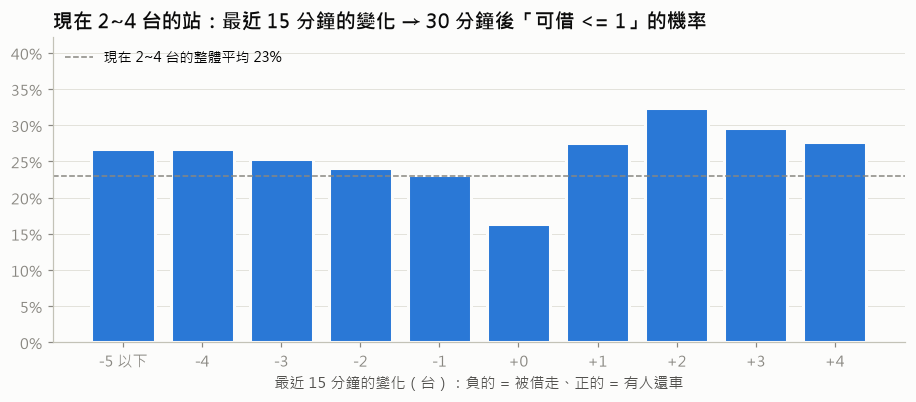

change15,-5.000000,-4.000000,-3.000000,-2.000000,-1.000000,0.000000,1.000000,2.000000,3.000000,4.000000
30 分鐘後 <= 1,26.7%,26.7%,25.4%,24.1%,23.1%,16.4%,27.5%,32.4%,29.6%,27.7%
樣本數,"12,700","7,181","12,467","22,212","42,312","116,508","54,708","30,981","10,921","3,001"


In [12]:
# 同樣是「現在 2~4 台」，最近 15 分鐘的變化有沒有差？
# 找每一列 15 分鐘前（±2.5 分鐘內）同一站的車輛數
past = df[["station_id", "src_time", "bikes_available"]].rename(
    columns={"src_time": "t_past", "bikes_available": "bikes_15min_ago"})
lab["_want"] = (lab["src_time"] - pd.Timedelta(minutes=15)).dt.as_unit("ms")
lab = pd.merge_asof(lab.sort_values("_want"), past.sort_values("t_past"),
                    left_on="_want", right_on="t_past", by="station_id",
                    direction="nearest", tolerance=pd.Timedelta(minutes=2.5)).drop(columns="_want")
lab["change15"] = (lab["bikes_available"] - lab["bikes_15min_ago"]).clip(-5, 5)

mid = lab[lab["bikes_available"].between(2, 4) & lab["bikes_15min_ago"].notna()]
p_by_change = mid.groupby("change15")["y"].agg(["mean", "size"])

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(p_by_change.index, p_by_change["mean"], color=C_WORK, width=0.8, edgecolor=SURFACE, linewidth=2)
ax.axhline(mid["y"].mean(), color=MUTED, linewidth=1, linestyle="--",
           label=f"現在 2~4 台的整體平均 {mid['y'].mean():.0%}")
ax.legend(loc="upper left", fontsize=9)
ax.set_ylim(0, p_by_change["mean"].max() * 1.3)
# 現在最多 4 台，15 分鐘前最少 0 台，所以「增加」最多 +4，只標實際有資料的刻度
ticks = [int(t) for t in p_by_change.index]
ax.set_xticks(ticks, ["-5 以下" if t == -5 else ("+5 以上" if t == 5 else f"{t:+d}") for t in ticks])
ax.set_xlabel("最近 15 分鐘的變化（台）：負的 = 被借走、正的 = 有人還車")
ax.yaxis.set_major_formatter(PCT)
ax.grid(axis="x", visible=False)
ax.set_title("現在 2~4 台的站：最近 15 分鐘的變化 → 30 分鐘後「可借 <= 1」的機率")
plt.show()
display(p_by_change.rename(columns={"mean": "30 分鐘後 <= 1", "size": "樣本數"}).T
        .style.format("{:.1%}", subset=pd.IndexSlice["30 分鐘後 <= 1", :])
        .format("{:,.0f}", subset=pd.IndexSlice["樣本數", :]))

**看到了什麼**

1. **大部分的「沒車」很短**：將近一半的段 10 分鐘內就有人還車（中位數 10 分鐘）。
   但**用時間算，約 6 成的沒車時間落在 30 分鐘以上的長段** —— 也就是說，
   有大量「一閃而過」的空，也有一些「空很久」的站（校區晚上一空就是好幾個小時）。
2. **為什麼「維持現狀」卡在 7 成**：
   - 現在 <= 1 的時候，30 分鐘後仍 <= 1 的約 68% → 它的精確率就卡在這裡，到不了 80%。
   - 30 分鐘後 <= 1 的情況裡，約 68% 現在就已經 <= 1 → 召回率也差不多。
   - **剩下約 32% 是「現在還有 2 台以上、30 分鐘後才變少」**，維持現狀永遠抓不到。
     這是模型真正要贏的地方。
   - 只看大安區時這兩個數字都是 60%；加進校區後變高，是因為校區晚上「空很久」，現在空、30 分鐘後也還空，很好猜。
3. **現在 2 台已經很危險**：30 分鐘後 <= 1 的機率約 32%，3 台約 20%，到 8 台以上才低於 4%。
4. **最近 15 分鐘的變化有用，但跟直覺不一樣**：同樣是現在 2~4 台，
   - 「15 分鐘都沒變」的最安全（約 16%）—— 安靜的站本來就不太會變；
   - 「被借走」的約 23 ~ 27%，符合直覺；
   - **「剛有人還車」的反而最危險（約 28 ~ 32%）** —— 因為它 15 分鐘前更少、甚至是 0 台，
     代表這是一個「剛剛才空過」的站，很快又會被借走。

**對建模的意義**：除了「現在幾台」，還要給模型**最近的歷史**：
15 / 30 分鐘前有幾台、最近是不是剛空過、站的活躍程度（變動大不大）。
單看「變多還是變少」的方向不夠，要讓模型自己學組合 —— 這也是為什麼要用樹模型而不是手寫規則。

## 1-3f 下雨有沒有影響？

天氣用大安區兩個自動氣象站（大安森林、臺灣大學 —— 後者就在校園裡）。雨量是**日累積值**，
一律先用 `rain_increment()` 換算成每 10 分鐘的雨量（見 `docs/DECISIONS.md`），
兩站取平均，再加總成「最近 30 分鐘下了多少」，> 0 就算「下雨中」。

In [13]:
w = rain_increment(load_weather(start=START, end=END, station_ids=DAAN_STATIONS))
rain10 = w.groupby(w["obs_time"].dt.floor("10min"))["rain_mm"].mean()   # 兩站平均
rain30 = rain10.rolling("30min").sum()                                    # 最近 30 分鐘的雨量

# 快照時間「往下」取整到 10 分鐘再對照：例如 08:07 的快照配 08:00 那筆觀測，
# 不會用到 08:10 才發布的觀測（那是未來的資訊）
df["rain30"] = df["src_time"].dt.floor("10min").map(rain30)
df["raining"] = df["rain30"] > 0

rain_days = (w.assign(date=w["time_taipei"].dt.strftime("%Y-%m-%d"))
               .groupby(["date", "station_id"])["rain_mm"].sum().unstack())
print("有下雨的日子（每站當天總雨量 mm）：")
print(rain_days[(rain_days > 0).any(axis=1)].rename(columns={"CAAH60": "大安森林", "A0A010": "臺灣大學"}))
slots = df.drop_duplicates("src_time")
print(f"\n18 天裡「下雨中」的時間點：{slots['raining'].sum()} / {slots['rain30'].notna().sum()}"
      f"（{slots['raining'].mean():.1%}）")

有下雨的日子（每站當天總雨量 mm）：
station_id  臺灣大學  大安森林
date                  
2026-10-01   0.0   3.5
2026-10-02  21.5   8.5
2026-10-03   1.0   1.0
2026-10-05  42.0  35.0

18 天裡「下雨中」的時間點：200 / 5058（3.9%）


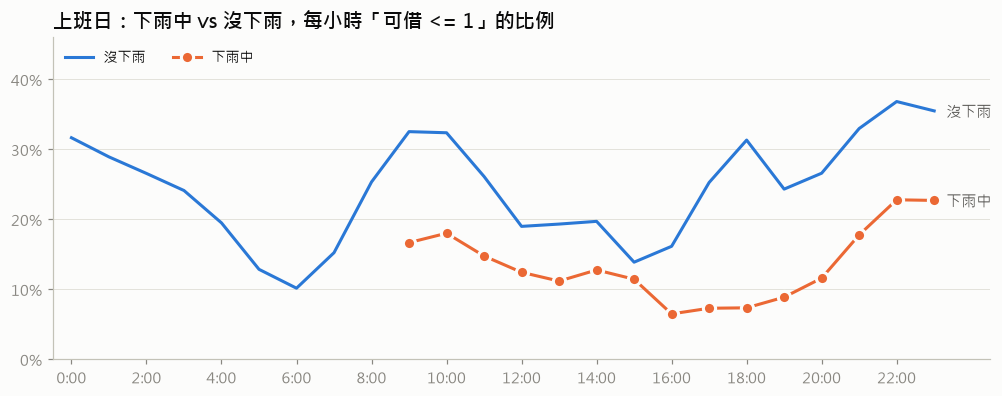

上班日整體：沒下雨 24.3%、下雨中 13.7%
每小時「下雨中」的時間點數（太少的小時參考價值低）：
hour  9   10  11  12  13  14  15  16  17  18  19  20  21  22  23
時間點數  12  12  12  12  12  14  18   4  12  12   6  20  12  12  12


In [14]:
work = df[(df["day_type"] == "上班日") & df["rain30"].notna()]
by_hour = work.groupby(["hour", "raining"])["empty1"].mean().unstack()
n_rain = work[work["raining"]].drop_duplicates("src_time").groupby("hour").size()

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(by_hour.index, by_hour[False], color=C_WORK, label="沒下雨")
ax.plot(by_hour.index, by_hour[True], color=C_OFF, label="下雨中", marker="o", markersize=8,
        markeredgecolor=SURFACE, markeredgewidth=2)
for col, color in [(False, C_WORK), (True, C_OFF)]:
    s = by_hour[col].dropna()
    ax.annotate("沒下雨" if not col else "下雨中", (s.index[-1], s.iloc[-1]), xytext=(8, 0),
                textcoords="offset points", va="center", fontsize=10, color=INK2)
ax.set_xticks(range(0, 24, 2), [f"{h}:00" for h in range(0, 24, 2)])
ax.set_xlim(-0.5, 24.5)
ax.set_ylim(0, by_hour.max().max() * 1.25)
ax.yaxis.set_major_formatter(PCT)
ax.legend(loc="upper left", ncol=2, fontsize=9)
ax.set_title("上班日：下雨中 vs 沒下雨，每小時「可借 <= 1」的比例")
plt.show()

overall = work.groupby("raining")["empty1"].mean()
print(f"上班日整體：沒下雨 {overall[False]:.1%}、下雨中 {overall[True]:.1%}")
print("每小時「下雨中」的時間點數（太少的小時參考價值低）：")
print(n_rain.to_frame("時間點數").T.to_string())

**看到了什麼**

1. **下雨時借不到車的比例大約只有一半**（上班日約 14% 對 24%），而且幾乎每個小時都是這樣。
   合理的解釋是：下雨騎車的人少，車子留在站裡。這跟 1-3b 看到「10/5 大雨那天全區總車數最多」一致。
2. **但證據還很薄**：18 天裡只有 4 天下過雨，「下雨中」的時間點只佔約 4%，
   而且約 6 成來自 10/5 一天。所以現在**分不清是「下雨」的效果，還是「10/5 那天」本身特別**。

**對建模的意義**：天氣特徵值得放進去（方向很合理），但現在不能下結論。
等累積到更多下雨天（尤其是上班日尖峰時段下雨）再回來看。

## 目前看到的重點（草稿，1-3g 會正式整理）

| 發現 | 對 phase 3 的特徵建議 |
|---|---|
| 上班日早上 10 點、晚上 22 點兩個高峰；休息日沒有早上尖峰 | 幾點 × 上班日 / 休息日 |
| 大安區是通勤型（早上空）、校區是校園型（晚上空），節奏相反 | 站的類型（所屬區）或站在這個時段的歷史空站率 |
| 10/9 補假比前後上班日低 | 要有國定假日行事曆，不能只看星期幾 |
| 10/13 那週整區少 3 成的車，比例跟著升高 | 全區（或附近）的總車數；評估要看不只一段測試期 |
| 最常空的前 15 站都在校區；車柱數關係不大 | 站的歷史空站率（只用訓練期算）、附近站的狀況 |
| 維持現狀精確率、召回率都卡在約 68%；32% 的「借不到」是從 >= 2 台變來的 | 15 / 30 分鐘前的車輛數、最近是否剛空過、站的活躍度 |
| 下雨時比例約減半，但只有 4 天雨 | 最近 30 分鐘雨量（先放，之後再驗證） |